# 3 · Choosing a graph builder

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vitormeriat/text4gcn/blob/main/docs/tutorials/03_choosing_a_graph_builder.ipynb)

The TextGCN graph of tutorial 2 connects two words whenever they co-occur
more often than chance. That gives **millions of edges**: most of the memory
and most of the build time.

The **Related Word Filter (RWF)** of Pereira & de Castro (DCAI 2022) asks a
simple question: *what if only related words were connected?* The semantic
variant trains Word2Vec on the corpus. It keeps a word–word edge only when the
two embeddings are very similar, and keeps the TF-IDF document–word edges
unchanged.

Here we build three graphs **on the same preprocessed corpus**, train the same
GCN on each and compare them.

> **Runtime:** about 4.5 min on a T4 GPU, almost all of it building the TF-IDF + PMI
> and Word2Vec RWF graphs (about 2 min each). Graph building runs on the CPU; a GPU
> speeds up only the training, which takes several times longer on CPU.

| # | Tutorial | Question it answers |
|---|---|---|
| 1 | Text as a graph | What does the graph look like, and why does it help? |
| 2 | Your first classifier | How do I go from raw text to test accuracy? |
| 3 | **Choosing a graph builder** | How should words be connected? |
| 4 | Refining the graph | Can a smaller graph do as well? |
| 5 | Bring your own corpus | How do I use my own (non-English) data? |

In [ ]:
%pip install -q text4gcn

In [2]:
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import text4gcn
from text4gcn import GNN, Builder, TextPipeline
from text4gcn.builder import Frequency, Semantic
from text4gcn.datasets import twenty_newsgroups
from text4gcn.utils import check_pytorch_installation, get_device_manager

In [3]:
print("text4gcn:", text4gcn.__version__)
print(check_pytorch_installation())   # torch version, cuda_available, CUDA version
print(get_device_manager().get_device_info())  # device the GNN will use

text4gcn: 2.0.0rc2
{'torch_version': '2.11.0+cu130', 'cuda_available': True, 'cuda_version': '13.0'}
{'device': 'cuda', 'type': 'cuda', 'is_cuda': True, 'is_cpu': False, 'cuda_version': '13.0', 'gpu_name': 'Tesla T4', 'gpu_memory': 15637086208, 'gpu_memory_gb': 15.637086208}


In [4]:
NAME = "20NG4"
DATA_DIR = Path("data")
LOG_DIR = Path("logs")
SEED = 1234
CATEGORIES = ["alt.atheism", "soc.religion.christian", "comp.graphics", "sci.med"]

Same data and preprocessing as tutorial 2: the graph is the only thing that changes.

In [5]:
shutil.rmtree(DATA_DIR, ignore_errors=True)   # start clean: outputs of older runs would be reused
twenty_newsgroups(DATA_DIR, name=NAME, categories=CATEGORIES)
TextPipeline(dataset_name=NAME, dataset_path=DATA_DIR, seed=SEED).execute(validation_ratio=0.10)

text4gcn · TextPipeline("20NG4") · language english · validation 10%
  ✓ clean     3,647 documents · 10,890 words kept (rare_count=5)  (0.8 s)
  ✓ shuffle   train 2,192 · test 1,455 documents (seed 1234)  (0.1 s)
  ✓ words     10,890 words · 9,179 with a WordNet definition  (5.6 s)
  ✓ features  train 1,973 · validation 219 · test 1,455 documents · 4 classes  (2.1 s)


## Three ways to connect words

| Graph | Word–word edges | `Builder` |
|---|---|---|
| **TF-IDF + PMI** (TextGCN) | positive PMI over a sliding window | `Builder.Tfidf` |
| **Word2Vec RWF** (DCAI 2022) | adjacent words whose corpus-trained Word2Vec embeddings have cosine similarity $\geq$ `threshold`, and positive PMI | `Builder.Word2Vec` |
| **Cosine similarity** | words whose WordNet definitions are similar: cosine of the TF-IDF vectors of their glosses $>$ `threshold` | `Builder.CosineSimilarity` |

All three keep the same TF-IDF document–word edges, so the graphs differ only in
their word–word edges. Each builder writes its
own adjacency file, and `GNN(builder=...)` selects which one to train on.

In [6]:
graphs = {
    "TF-IDF + PMI": (Builder.Tfidf,
                     lambda: Frequency(dataset_name=NAME, dataset_path=DATA_DIR).tfidf(window_size=20)),
    "Word2Vec RWF": (Builder.Word2Vec,
                     lambda: Semantic(dataset_name=NAME, dataset_path=DATA_DIR).word2vec(
                         training_algorithm=1,      # 1 = skip-gram, 0 = CBOW
                         embedding_dimension=300, num_epochs=20, threshold=0.7)),
    "Cosine similarity": (Builder.CosineSimilarity,
                          lambda: Semantic(dataset_name=NAME, dataset_path=DATA_DIR).cosine_similarity(
                              threshold=0.95)),
}

In [7]:
rows = []
for name, (builder, build) in graphs.items():
    start = time.perf_counter()
    stats = build()
    build_seconds = time.perf_counter() - start

    result = GNN(dataset_name=NAME, dataset_path=DATA_DIR, log_dir=LOG_DIR / builder.value,
                 builder=builder, seed=SEED).fit()
    rows.append({
        "graph": name,
        "edges": stats.n_edges,
        "word–word": stats.word_word_edges,
        "file (MiB)": stats.file_bytes / 2**20,
        "build (s)": build_seconds,
        "test accuracy": result.test_accuracy,
        "epochs": result.epochs_trained,
    })

comparison = pd.DataFrame(rows).set_index("graph")
comparison.style.format({"edges": "{:,}", "word–word": "{:,}", "file (MiB)": "{:.1f}", "build (s)": "{:.0f}",
                         "test accuracy": "{:.2%}"})

text4gcn · Frequency.tfidf("20NG4") · window 20


  ✓ graph     14,537 nodes · 4.53 M edges (4.26 M word–word) · density 2.15% · 52.0 MiB  (2m07s)
text4gcn · GNN("20NG4") · frequency.tfidf · cuda (Tesla T4) · seed 1234
  graph     14,537 nodes: 1,973 train · 219 validation · 1,455 test documents + 10,890 words
  model     GCN 14,537 → 200 → 4 · 2.91 M parameters · dropout 0.5 · lr 0.02
  ✓ train     68 epochs (early stop) · best epoch 64 (val_loss 1.3679, val_acc 93.6%)  (6.7 s)                            
  ✓ test      accuracy 86.7% · macro-F1 86.1% · loss 1.2910 · 1,455 documents  (<0.1 s)

                     class  precision  recall    f1  support
    soc.religion.christian      0.798   0.885 0.840      384
                   sci.med      0.934   0.889 0.911      379
               alt.atheism      0.804   0.718 0.759      309
             comp.graphics      0.923   0.945 0.934      383

  model     logs/frequency.tfidf/20261017-233705821.pth
text4gcn · Semantic.word2vec("20NG4") · skip-gram · 300 dims · 20 epochs · threshold 0.

,edges,word–word,file (MiB),build (s),test accuracy,epochs
graph,,,,,,
TF-IDF + PMI,"4,534,779","4,258,440",52.0,127,86.67%,68
Word2Vec RWF,"279,559","3,220",3.3,107,85.64%,50
Cosine similarity,"293,629","17,290",3.4,6,85.22%,48


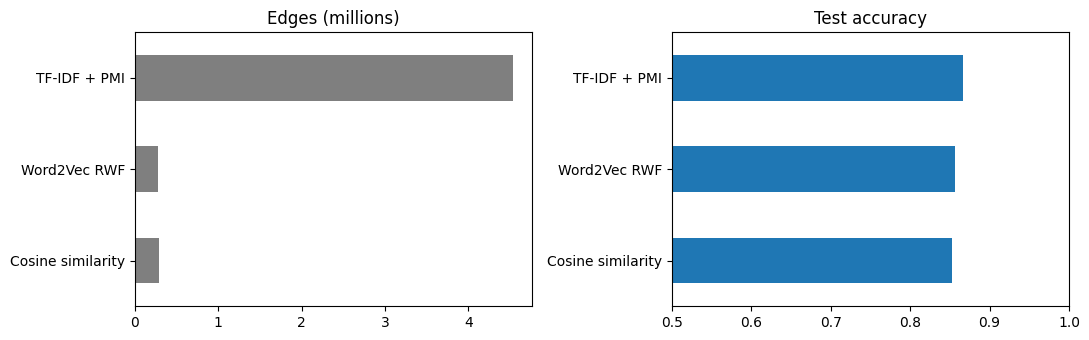

In [8]:
fig, (ax_edges, ax_acc) = plt.subplots(1, 2, figsize=(11, 3.5))
(comparison["edges"] / 1e6).plot.barh(ax=ax_edges, color="tab:gray", title="Edges (millions)")
comparison["test accuracy"].plot.barh(ax=ax_acc, color="tab:blue", title="Test accuracy", xlim=(0.5, 1))
for ax in (ax_edges, ax_acc):
    ax.set_ylabel("")
    ax.invert_yaxis()
plt.tight_layout()

## Reading the results

On our GPU run (seed 1234):

* The **Word2Vec RWF graph had $16\times$ fewer edges** (0.28 M vs 4.5 M), a 3.3 MiB file
  instead of 52 MiB, and took about the same time to build (~2 min: 1m47s vs 2m07s). It lost about one point of accuracy
  (85.6% vs 86.7%). This is the trade-off reported in the DCAI 2022 paper:
  **much smaller graphs with comparable accuracy**.
* The **word–word** column shows where the difference lies (each word–word edge is
  stored in both directions). The PMI of TextGCN adds 4.3 M word–word entries. The
  RWF keeps 3,220 and the cosine graph 17,290: both graphs are almost entirely
  made of the TF-IDF document–word edges.
* The RWF and cosine graphs differ by only **about 0.4 points** (85.6% vs 85.2%), and
  both are only 1–1.5 points below TextGCN's 86.7%, with $16\times$ fewer edges. Their
  weights explain part of it: an RWF edge weighs its pair count divided by the largest
  pair count, so it is at most 1 and usually much lighter than a TF-IDF
  document–word edge.

On this corpus the **document–word edges carry most of the signal**. The 4.3 M PMI
edges buy about one point of accuracy; the RWF and cosine word–word edges change
graph size a lot and accuracy only slightly.

Which one to choose:

* **Start with TF-IDF + PMI.** It is the TextGCN baseline and the most accurate here.
* **Use Word2Vec RWF** when memory matters: about one point less for a
  $16\times$ smaller graph.
* **`threshold`** sets the size of the RWF graph. Measure accuracy on your own data
  before tuning it.
* The cosine graph compares WordNet definitions, so it is meaningful for English only.
* The syntactic graphs (`Syntactic.dependency_parsing()`, `Syntactic.linguistic_inquiry()`)
  follow the same pattern but need a local Stanford CoreNLP installation or a LIWC
  dictionary; `dependency_parsing()` is marked experimental. See the
  [builders guide](https://vitormeriat.github.io/text4gcn/guides/builders/).

**Next:** the builder decides which edges exist. [4 · Refining the graph](https://vitormeriat.github.io/text4gcn/tutorials/04_refining_the_graph/)
prunes an existing graph instead, without rebuilding it.